# Accuracy of Averages and Confidence Intervals: Python Functions
**ENGR 1451/2451 · Exploratory Data Science · w09a**

Practice the SciPy functions used to estimate the standard error and construct confidence intervals for a **population mean**. Run cells in order, and keep the included `data` folder beside this notebook.

**Real-data default:** the population SD $\sigma$ is generally **unknown**. Estimate it using the sample SD $s$, then use Student's $t$ for a confidence interval.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats

pd.set_option("display.precision", 4)


## 1. Estimate an SE: `np.sqrt()`

From the lecture's family-income survey: $n=1000$, sample mean $\bar{x}=\$62{,}396.714$, and sample SD $s\approx\$53{,}000$.

Because the population SD is **not known**, estimate the SE with $\widehat{\mathrm{SE}}(\bar X)=s/\sqrt{n}$. The estimated SE measures uncertainty in the **sample mean**, not the spread of individual incomes.


In [2]:
income_n = 1000
income_mean = 62_396.714
income_s = 53_000  # approximate sample SD from slides
income_se = income_s / np.sqrt(income_n)

pd.Series({
    "Sample mean ($)": income_mean,
    "Sample SD ($)": income_s,
    "Estimated SE of the mean ($)": income_se,
})


Sample mean ($)                 62396.7140
Sample SD ($)                   53000.0000
Estimated SE of the mean ($)     1676.0072
dtype: float64

## 2. Compare distributions: `stats.norm.pdf()` and `stats.t.pdf()`

The $t$ distribution has heavier tails. For a one-sample mean, its degrees of freedom are $df=n-1$. For larger $df$, it approaches the standard normal distribution.

Use `pdf()` to evaluate the height of each density curve at an array of $x$ values.


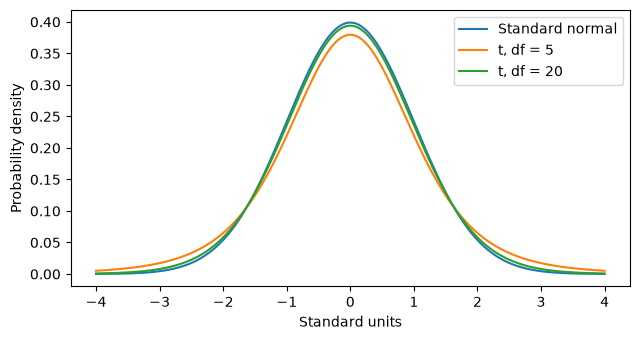

In [3]:
x = np.linspace(-4, 4, 400)

plt.figure(figsize=(6.5, 3.5))
plt.plot(x, stats.norm.pdf(x), label="Standard normal")
plt.plot(x, stats.t.pdf(x, df=5), label="t, df = 5")
plt.plot(x, stats.t.pdf(x, df=20), label="t, df = 20")
plt.xlabel("Standard units")
plt.ylabel("Probability density")
plt.legend()
plt.tight_layout()
plt.show()


## 3. Find the critical value: `stats.t.ppf()`

For a 95% CI, $\alpha=0.05$. `ppf()` uses the **left-tail probability**, so the positive critical value is computed as

$$t^* = \mathrm{stats.t.ppf}(1-\alpha/2,\;df=n-1).$$

The value $1.96$ comes from `stats.norm.ppf(1 - alpha / 2)`. Compare it with $t^*$ for different sample sizes.


In [4]:
sample_sizes = np.array([5, 10, 20, 30, 100, 1000])
alpha = 0.05

pd.DataFrame({
    "n": sample_sizes,
    "df": sample_sizes - 1,
    "95% t*": stats.t.ppf(1 - alpha / 2, df=sample_sizes - 1),
    "95% z*": stats.norm.ppf(1 - alpha / 2),
})


,n,df,95% t*,95% z*
0,5,4,2.7764,1.96
1,10,9,2.2622,1.96
2,20,19,2.0930,1.96
3,30,29,2.0452,1.96
4,100,99,1.9842,1.96
5,1000,999,1.9623,1.96


## 4. Construct a CI: `stats.t.ppf()` and arithmetic

In real data we usually know only $n$, $\bar{x}$, and $s$. A one-sample 95% CI for the population mean is

$$\bar{x}\pm t^*_{n-1}\frac{s}{\sqrt n}.$$

Use the family-income summary above. Compare the $t$ margin of error with the lecture's shortcut $2\times\widehat{\mathrm{SE}}$. Small differences from the slide's rounded bounds are expected.


In [5]:
income_tstar = stats.t.ppf(1 - alpha / 2, df=income_n - 1)
income_margin = income_tstar * income_se
income_ci = (income_mean - income_margin, income_mean + income_margin)

pd.Series({
    "95% t critical value": income_tstar,
    "Estimated SE ($)": income_se,
    "t margin of error ($)": income_margin,
    "95% CI lower ($)": income_ci[0],
    "95% CI upper ($)": income_ci[1],
    "2 x SE shortcut margin ($)": 2 * income_se,
})


95% t critical value              1.9623
Estimated SE ($)               1676.0072
t margin of error ($)          3288.8983
95% CI lower ($)              59107.8157
95% CI upper ($)              65685.6123
2 x SE shortcut margin ($)     3352.0143
dtype: float64

## 5. Use real engineering measurements: `pd.read_csv()` and `stats.sem()`

The included NIST dataset contains 101 aluminum fatigue lifetimes (in **thousands of cycles**) measured at 21,000 psi. Here, $\sigma$ is unknown.

`std(ddof=1)` computes the sample SD, while `stats.sem(values, ddof=1)` computes the **estimated** SE of the mean. For the interval to describe a broader testing process, we assume the specimens are independent and representative of that process. With $n=101$, this is an approximate $t$ interval for the population mean.

Source: [NIST aluminum fatigue case study](https://www.itl.nist.gov/div898/handbook/eda/section4/eda4291.htm).


In [6]:
fatigue = pd.read_csv("data/nist_aluminum_fatigue_21000psi.csv")
lifetime = fatigue["fatigue_life_thousand_cycles"]

pd.Series({
    "Number of specimens": lifetime.size,
    "Sample mean (thousand cycles)": lifetime.mean(),
    "Sample SD (thousand cycles)": lifetime.std(ddof=1),
    "Estimated SE (thousand cycles)": stats.sem(lifetime, ddof=1),
})


Number of specimens                101.0000
Sample mean (thousand cycles)     1400.9109
Sample SD (thousand cycles)        391.3241
Estimated SE (thousand cycles)      38.9382
dtype: float64

## 6. Calculate a CI directly: `stats.t.interval()`

`stats.t.interval(confidence, df, loc, scale)` returns the lower and upper bounds for the $t$ distribution centered at `loc`, with scale `scale`.

For the **mean**, supply `loc=sample mean`, `scale=estimated SE`, and `df=n-1`—not the sample SD as `scale`. Check that `ppf()` and `interval()` give the same bounds for the **same fatigue data**.


In [7]:
fatigue_mean = lifetime.mean()
fatigue_se = stats.sem(lifetime, ddof=1)
fatigue_df = lifetime.size - 1

# Method 1: critical value and margin of error
fatigue_tstar = stats.t.ppf(1 - alpha / 2, df=fatigue_df)
fatigue_ci_ppf = (fatigue_mean - fatigue_tstar * fatigue_se,
                  fatigue_mean + fatigue_tstar * fatigue_se)

# Method 2: calculate the interval directly
fatigue_ci = stats.t.interval(
    confidence=1 - alpha,
    df=fatigue_df,
    loc=fatigue_mean,
    scale=fatigue_se,
)

pd.Series({
    "Mean (thousand cycles)": fatigue_mean,
    "Estimated SE (thousand cycles)": fatigue_se,
    "95% CI lower from ppf()": fatigue_ci_ppf[0],
    "95% CI upper from ppf()": fatigue_ci_ppf[1],
    "95% CI lower from interval()": fatigue_ci[0],
    "95% CI upper from interval()": fatigue_ci[1],
})

Mean (thousand cycles)            1400.9109
Estimated SE (thousand cycles)      38.9382
95% CI lower from ppf()           1323.6586
95% CI upper from ppf()           1478.1632
95% CI lower from interval()      1323.6586
95% CI upper from interval()      1478.1632
dtype: float64

## 7. Short practice

**Exercise 1 — A random sample of $n=900$ students has $\bar{x}=22.3$ years and $s=4.5$ years. Use `stats.t.ppf()` to calculate the 95% $t$ confidence interval. Compare your answer with the lecture's approximate interval of **22.0 to 22.6 years**.


In [19]:
# Add your calculations here.
n = 900
mean = 22.3
s = 4.5

confidence_level = 0.95
input_CL = confidence_level + (1-confidence_level)/2

sample_se = s/np.sqrt(n)

t_star = stats.t.ppf(input_CL, df = n-1)
margin_of_error = t_star*sample_se

ci = (mean - margin_of_error, mean + margin_of_error)
print(ci)

(np.float64(22.00560905960605), np.float64(22.59439094039395))


**Exercise 2 — Change the confidence level.** Recalculate the aluminum-fatigue confidence interval using **90%** instead of 95%, with `stats.t.interval()`. Print the two bounds, and check whether the 90% interval is narrower than the 95% interval.


In [22]:
# Add your calculations here.

confidence_level = 0.90
input_CL = confidence_level + (1-confidence_level)/2

t_star_new = stats.t.ppf(input_CL, df = n-1)
margin_of_error_new = t_star_new*sample_se

ci_new = (mean - margin_of_error_new, mean + margin_of_error_new)
print(ci_new)

(np.float64(22.053017448150317), np.float64(22.546982551849684))


### General Python function reference

| Purpose | General syntax | Notes |
|---|---|---|
| Sample mean | `series.mean()` | Ignores missing values by default. |
| Sample SD | `series.std(ddof=1)` | Uses denominator $n-1$. |
| Estimated SE of a mean | `stats.sem(values, ddof=1)` | Returns $s/\sqrt n$. |
| Normal density | `stats.norm.pdf(x)` | Evaluates density at x-values. |
| Student's t density | `stats.t.pdf(x, df=...)` | Requires degrees of freedom. |
| Normal critical value | `stats.norm.ppf(p)` | Left-tail probability `p`. |
| Student's t critical value | `stats.t.ppf(p, df=...)` | For a two-sided 95% CI, `p=1 - alpha / 2`. |
| Student's t interval | `stats.t.interval(confidence, df, loc, scale)` | For a mean, use `loc=mean` and `scale=SE`. |

Use `help(function_name)` or `function_name?` in Jupyter to see function arguments.

**Interpretation reminder:** A 95% CI procedure has approximately 95% long-run coverage when its sampling/modeling assumptions hold. The population mean is fixed; the interval varies with the sample.
